In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
import numpy as np
import cv2

import warnings
warnings.filterwarnings('ignore')

from tensorflow import keras
from keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

import os
import matplotlib.image as mpimg

data = pd.read_csv(r'C:\Users\SuNi\Downloads\cat and dog.csv')
data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("Shape of train_data:", data.shape)
data.info()

Shape of train_data: (42000, 785)
<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB


In [6]:
data.describe()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
count,42000.000000,42000.0,42000.0,42000.0,42000.0,42000.0,42000.0,42000.0,42000.0,42000.0,...,42000.000000,42000.000000,42000.000000,42000.00000,42000.000000,42000.000000,42000.0,42000.0,42000.0,42000.0
mean,4.456643,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.219286,0.117095,0.059024,0.02019,0.017238,0.002857,0.0,0.0,0.0,0.0
std,2.887730,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,6.312890,4.633819,3.274488,1.75987,1.894498,0.414264,0.0,0.0,0.0,0.0
min,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.0,0.0,0.0
25%,2.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.0,0.0,0.0
50%,4.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.0,0.0,0.0
75%,7.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.0,0.0,0.0,0.0
max,9.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,254.000000,254.000000,253.000000,253.00000,254.000000,62.000000,0.0,0.0,0.0,0.0


In [7]:
print(data.duplicated().sum())
data.isnull().sum()

0


label       0
pixel0      0
pixel1      0
pixel2      0
pixel3      0
           ..
pixel779    0
pixel780    0
pixel781    0
pixel782    0
pixel783    0
Length: 785, dtype: int64

In [8]:
from tensorflow.keras.utils import to_categorical

X = data.drop(['label'], axis=1).values.astype("float32") / 255.0
y = data['label'].values
 
X = X.reshape(-1, 28, 28, 1)
y_cat = to_categorical(y, 10)

print("Shape of X after separating features:", X.shape)
print("Shape of X after reshaping:", X.shape)

Shape of X after separating features: (42000, 28, 28, 1)
Shape of X after reshaping: (42000, 28, 28, 1)


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y_cat, test_size=0.2, random_state=0)

print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)

(33600, 28, 28, 1) (33600, 10)
(8400, 28, 28, 1) (8400, 10)


In [10]:
model = tf.keras.models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),
    Dropout(0.2),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),
    Dropout(0.2),
    
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.1),
    layers.Dense(10, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,930 (882.54 KB)

 Trainable params: 225,482 (880.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [11]:
early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)

history = model.fit(
    X_train, y_train, 
    epochs=10, 
    batch_size=64, 
    validation_data=(X_test, y_test),
    callbacks=[early_stop]
)

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 65s 105ms/step - accuracy: 0.9422 - loss: 0.1878 - val_accuracy: 0.9274 - val_loss: 0.2663
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 52s 98ms/step - accuracy: 0.9786 - loss: 0.0679 - val_accuracy: 0.9867 - val_loss: 0.0430
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 52s 98ms/step - accuracy: 0.9851 - loss: 0.0491 - val_accuracy: 0.9880 - val_loss: 0.0375
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 52s 99ms/step - accuracy: 0.9867 - loss: 0.0418 - val_accuracy: 0.9881 - val_loss: 0.0366
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 53s 101ms/step - accuracy: 0.9889 - loss: 0.0347 - val_accuracy: 0.9904 - val_loss: 0.0327
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 50s 96ms/step - accuracy: 0.9905 - loss: 0.0297 - val_accuracy: 0.9911 - val_loss: 0.0315
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 53s 101ms/step - accuracy: 0.9916 - loss: 0.0263 - val_accuracy: 0.9893 - val_loss: 0.0312
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 46s 88ms/step - accuracy: 0.9929 - loss: 0.0219

In [12]:
from sklearn.metrics import confusion_matrix , ConfusionMatrixDisplay, classification_report

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f'Test Accuracy: {acc:.4f}')
print(f'Test Loss: {loss:.4f}')

pred = model.predict(X_test).argmax(axis=1)
true = y_test.argmax(axis=1)
print("Classification Report: \n", classification_report(true, pred))

Test Accuracy: 0.9905
Test Loss: 0.0280
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      1.00      1.00       813
           1       0.99      1.00      0.99       961
           2       0.99      0.99      0.99       860
           3       1.00      0.98      0.99       863
           4       1.00      0.99      0.99       827
           5       0.98      0.99      0.99       756
           6       0.99      1.00      0.99       841
           7       0.98      0.99      0.99       899
           8       0.99      0.99      0.99       768
           9       0.99      0.98      0.99       812

    accuracy                           0.99      8400
   macro avg       0.99      0.99      0.99      8400
weighted avg       0.99      0.99      0.99      8400



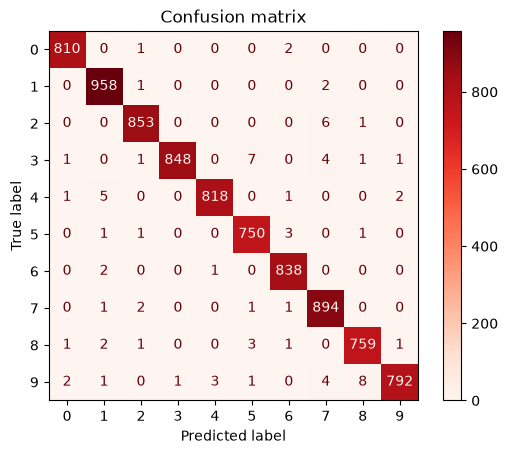

In [13]:
cm = confusion_matrix(true, pred)
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(cmap='Reds')
plt.title("Confusion matrix")
plt.show()

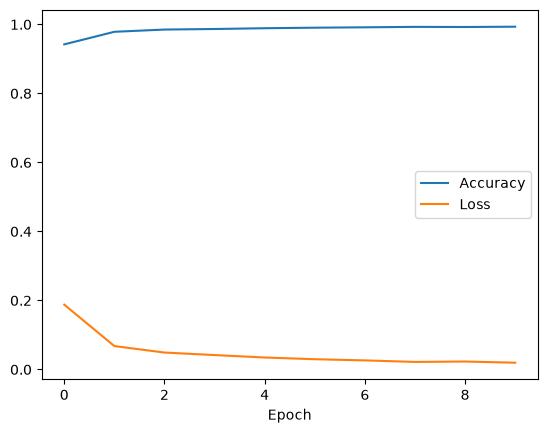

In [14]:
plt.plot(history.history['accuracy'], label='Accuracy')
plt.plot(history.history['loss'], label = 'Loss')
plt.xlabel('Epoch')
plt.legend()
plt.show()